# Figure 4: Reach and concentration

Rebuild the reach ratios for ImageJ/Fiji, other analysis packages and microscope-control programs. Panel a counts distinct papers in each group. Panel b gives the ImageJ/Fiji share of analysis-package mentions with and without microscope-control software.

## Inputs

| Committed file | Contents | Producer |
| --- | --- | --- |
| `config/tools.yml` | Curated aliases, categories and query context | Manual registry, read by `python -m census.build.build_dataset` |
| `data/processed/tools.csv` | Package names, categories, scope and aggregate flags | `python -m census.build.build_dataset` |
| `data/processed/literature_yearly.csv` | Yearly package mention counts by source | `python -m census.build.build_dataset` |
| `data/processed/corpus_yearly.csv` | Yearly indexed full-text microscopy denominator | `python -m census.build.build_dataset` |
| `data/processed/reach_any_yearly.csv` | Distinct-paper counts from each group OR query | `python -m census.build.build_reach_any` |

Input paths are relative to the repository root. The closing check also reads `../MANUSCRIPT/FIGURES/Figure4__reach.png` when present. The manuscript image is optional and stays outside a public clone.

## Set up offline analysis

Locate the repository in either layout, load the package registry and import the shared publication renderer. This cell makes no API requests.

In [1]:
from pathlib import Path
from io import BytesIO
from tempfile import TemporaryDirectory
import sys
import hashlib

import numpy as np
import pandas as pd
from IPython.display import Image, display
from PIL import Image as PILImage
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
SCRIPTS_DIR = next(p for p in (cwd, *cwd.parents) if (p / 'census' / '_registry.py').is_file())
REPO_ROOT = SCRIPTS_DIR.parent
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from census._registry import build_boolean_query, load_registry
from census.figures import fig4_reach as figure
from census.figures import style as fs

reg = load_registry()
def inspect_processed(name, columns=None):
    frame = fs.load(name)
    print(f'{name}: shape={frame.shape}')
    display((frame if columns is None else frame[columns]).head())
    return frame


## Registry and query construction

The shared query context restricts the registry aliases to microscopy papers with indexed full text. The aggregate flag includes 28 packages. The analysis group contains 22 packages and excludes six microscope-control programs, MATLAB and Jupyter notebooks.

In [2]:
registry_table = pd.DataFrame([
    {'tool_id': tool.id, 'name': tool.name, 'category': tool.category, 'scope': tool.scope,
     'in_aggregate': tool.in_aggregate, 'aliases': ' | '.join(tool.aliases),
     'query': build_boolean_query(tool, reg.context_query)}
    for tool in reg.tools
])
print(f'{len(reg.tools)} packages; years {reg.year_start}-{reg.year_end}')
print(f'Shared context: {reg.context_query}')
print(f'Registry table shape: {registry_table.shape}')
display(registry_table.drop(columns='query').head(8))
display(registry_table.loc[registry_table.tool_id.isin(['imagej', 'zen', 'cellpose']), ['tool_id', 'aliases', 'query']])

30 packages; years 2010-2025
Shared context: (microscopy OR microscope) AND HAS_FT:Y
Registry table shape: (30, 7)


,tool_id,name,category,scope,in_aggregate,aliases
0,jupyter,Jupyter notebooks,notebook,core,False,Jupyter | Jupyter notebook | IPython notebook
1,imagej,ImageJ / Fiji,general-platform,core,True,ImageJ | ImageJ2 | Fiji | FIJI
2,napari,napari,general-platform,core,True,napari
3,cellprofiler,CellProfiler,general-platform,core,True,CellProfiler
4,qupath,QuPath,general-platform,core,True,QuPath
5,icy,Icy,general-platform,core,True,Icy bioimage | Icy software | de Chaumont Icy
6,ilastik,ilastik,general-platform,core,True,ilastik
7,knime,KNIME,general-platform,core,True,KNIME


,tool_id,aliases,query
1,imagej,ImageJ | ImageJ2 | Fiji | FIJI,"(""ImageJ2"" OR ""ImageJ"" OR ""Fiji"" OR ""FIJI"") AN..."
8,cellpose,Cellpose,"""Cellpose"" AND ((microscopy OR microscope) AND..."
26,zen,ZEN blue | ZEN black | ZEN software | Zeiss ZE...,"(""ZEN software"" OR ""ZEN black"" OR ""Zeiss ZEN"" ..."


## Read panel inputs

Load the committed data for the calculations below. Panel a uses distinct-paper group counts for reach. Panel b shows ImageJ/Fiji concentration with and without microscope-control programs. We also check the bounds from summed mentions.

In [3]:
inspect_processed('literature_yearly.csv')
inspect_processed('corpus_yearly.csv')
inspect_processed('tools.csv')
reach_any = inspect_processed('reach_any_yearly.csv')


literature_yearly.csv: shape=(960, 4)


,source,tool_id,year,count
0,openalex,jupyter,2010,0
1,openalex,jupyter,2011,0
2,openalex,jupyter,2012,0
3,openalex,jupyter,2013,0
4,openalex,jupyter,2014,0


corpus_yearly.csv: shape=(16, 2)


,year,microscopy_papers
0,2010,42806
1,2011,49532
2,2012,58343
3,2013,66112
4,2014,70986


tools.csv: shape=(30, 7)


,tool_id,name,category,implies_dl,in_aggregate,scope,homepage
0,jupyter,Jupyter notebooks,notebook,False,False,core,https://jupyter.org
1,imagej,ImageJ / Fiji,general-platform,False,True,core,https://imagej.net
2,napari,napari,general-platform,False,True,core,https://napari.org
3,cellprofiler,CellProfiler,general-platform,False,True,core,https://cellprofiler.org
4,qupath,QuPath,general-platform,False,True,core,https://qupath.github.io


reach_any_yearly.csv: shape=(48, 3)


,year,group,papers
0,2010,analysis,5013
1,2011,analysis,6852
2,2012,analysis,8838
3,2013,analysis,11041
4,2014,analysis,12593


## Reconstruct panel quantities

Panel a uses distinct-paper group counts for reach. Panel b shows ImageJ/Fiji concentration with and without microscope-control programs. We also check the bounds from summed mentions.

In [4]:
analysis_ids = fs.analysis_tools()
aggregate_ids = fs.aggregate_tools()
control_ids = [tool for tool in aggregate_ids if tool not in analysis_ids]
other_analysis_ids = [tool for tool in analysis_ids if tool != 'imagej']
groups = {
    'ImageJ/Fiji': ['imagej'],
    'Other 21 analysis packages': other_analysis_ids,
    'Six microscope-control programs': control_ids,
}
reach = pd.DataFrame({label: fs.reach(tool_ids) for label, tool_ids in groups.items()})
print(f'Analysis packages: {len(analysis_ids)}; controls: {len(control_ids)}; aggregate packages: {len(aggregate_ids)}')
display(reach.loc[[2010, 2020, 2025]])

concentration = []
for group in ['analysis', 'all']:
    shares = fs.share_of_total(group)
    imagej = shares.loc[shares.tool_id.eq('imagej')].set_index('year')['share']
    for year in [2010, 2020, 2025]:
        concentration.append({'group': group, 'year': year, 'imagej_share_percent': imagej.loc[year]})
display(pd.DataFrame(concentration))

corpus = fs.corpus()
print(f'Indexed microscopy papers: {int(corpus.loc[2010]):,} in 2010; {int(corpus.loc[2025]):,} in 2025.')
# Panel a: one OR query per group counts each paper once, so a paper mentioning several packages
# contributes to the group count once (build_reach_any.py).
grouped = reach_any.pivot(index='year', columns='group', values='papers')
panel_a = (100 * grouped.div(fs.corpus().reindex(grouped.index), axis=0)).round(1)
display(panel_a.loc[[2010, 2020, 2025]])

# The union bounds the summed single-package matches from below and the largest single package
# from above; the summed matches in turn bound the union from above.
yearly = fs.europepmc_yearly().pivot(index='year', columns='tool_id', values='count')
assert list(grouped.columns) == ['analysis', 'microscope_control', 'other_analysis']
assert (grouped.other_analysis <= grouped.analysis).all()
assert (grouped.analysis <= yearly[analysis_ids].sum(axis=1).reindex(grouped.index)).all()
assert (grouped.analysis >= yearly[analysis_ids].max(axis=1).reindex(grouped.index)).all()
assert (yearly.imagej.reindex(grouped.index) <= grouped.analysis).all()
assert (grouped.microscope_control <= yearly[control_ids].sum(axis=1).reindex(grouped.index)).all()
assert (grouped.max(axis=1) <= fs.corpus().reindex(grouped.index)).all()
print(f'Union bounds hold for all {len(grouped)} years; the analysis-package share rises from {panel_a.analysis.loc[2010]:.0f}% to {panel_a.analysis.loc[2025]:.0f}%.')


Analysis packages: 22; controls: 6; aggregate packages: 28


,ImageJ/Fiji,Other 21 analysis packages,Six microscope-control programs
year,,,
2010,10.447134,2.632808,8.519834
2020,21.924346,3.778282,7.750265
2025,27.771513,6.040325,7.073828


,group,year,imagej_share_percent
0,analysis,2010,79.871406
1,analysis,2020,85.300017
2,analysis,2025,82.135472
3,all,2010,48.366861
4,all,2020,65.537967
5,all,2025,67.924815


Indexed microscopy papers: 42,806 in 2010; 177,358 in 2025.


group,analysis,microscope_control,other_analysis
year,,,
2010,11.7,7.9,2.4
2020,23.5,7.2,3.4
2025,30.0,6.6,5.0


Union bounds hold for all 16 years; the analysis-package share rises from 12% to 30%.


## Rebuilding from scratch

All default cells run offline from the committed inputs above. Source collectors need network access when their raw API caches are absent. `python -m census.build.build_dataset` collects counts and snapshots, the specialised producer modules listed under Inputs rebuild their own derived tables. Snapshots retain their original collection date.

To restore sampled titles and abstracts, run `python release/refetch_identifiers.py` with network access. The refetched corpus supports vocabulary classification and research-area calculations. A public clone omits that corpus and the raw response caches. These notebooks display derived data and never fetch records during execution.

## Render all panels

Build `Figure4__reach` with the shared 300 dpi publication style. Save PNG, PDF and SVG in a temporary directory and retain the full-size PNG pixels for the closing check. Display a scaled preview.

wrote Figure4__reach.png/.pdf/.svg
Figure4__reach: 2100 x 745 pixels


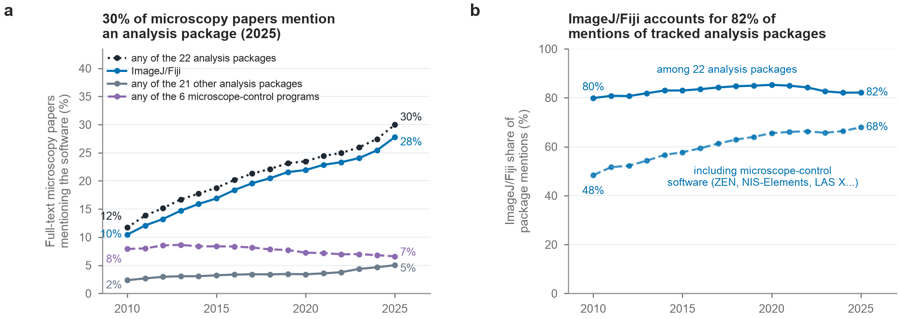

In [5]:
OUTPUT_STEM = 'Figure4__reach'
fig = figure.build_figure()
with TemporaryDirectory(prefix='notebook-render-') as output_dir:
    fs.save(fig, OUTPUT_STEM, out_dir=output_dir)
    png_bytes = (Path(output_dir) / (OUTPUT_STEM + '.png')).read_bytes()
rendered_pixels = np.asarray(PILImage.open(BytesIO(png_bytes)).convert('RGBA'))
print(f'{OUTPUT_STEM}: {rendered_pixels.shape[1]} x {rendered_pixels.shape[0]} pixels')
preview = PILImage.open(BytesIO(png_bytes))
preview.thumbnail((900, 900))
preview_bytes = BytesIO()
preview.save(preview_bytes, format='PNG')
display(Image(data=preview_bytes.getvalue(), width=min(640, preview.width)))
plt.close('all')


## Historical variant

`Figure4_new_dlwithintool` is an earlier within-package deep-learning estimator figure in the manuscript working folder. The current paper cites `Figure4__reach`. This notebook reproduces the current reach figure, the historical PNG is outside the publication targets.

## Check against the manuscript

Assert exact pixel equality, including image dimensions and every panel, when the manuscript PNG exists. A public clone prints a skip note for that comparison and still checks that rendering produced pixels. The pixel hash supports comparisons across runs.

In [6]:
assert rendered_pixels.size > 0
reference = REPO_ROOT / 'MANUSCRIPT' / 'FIGURES' / (OUTPUT_STEM + '.png')
if reference.is_file():
    expected_pixels = np.asarray(PILImage.open(reference).convert('RGBA'))
    assert rendered_pixels.shape == expected_pixels.shape, 'Manuscript image dimensions differ'
    np.testing.assert_array_equal(rendered_pixels, expected_pixels)
    print(f'{OUTPUT_STEM}: identical to manuscript PNG (all pixels, all panels)')
else:
    print(f'{OUTPUT_STEM}: manuscript comparison skipped; manuscript PNG is absent in this clone')
print('Rendered pixel SHA-256:', hashlib.sha256(rendered_pixels.tobytes()).hexdigest())


Figure4__reach: identical to manuscript PNG (all pixels, all panels)
Rendered pixel SHA-256: 05deae22161a7d2bc03f4575211a7f2d566d8c6d951ef156d3f8284a5a9ece0c
